# TexTag: CLIP comparison (model 3)

**CLIP** is a pretrained model that learned from ~400 million images with their captions.
It has two parts:

- an **image encoder**: image in → 512 numbers out
- a **text encoder**: text in → 512 numbers out

It was trained so that a matching image and text get **similar numbers**
(a photo of a brick wall and the text "brick wall" end up close together).

We try it two ways and compare with our models:

| | What trains | Like |
|---|---|---|
| **Zero-shot** | Nothing. Compare each image with 47 sentences ("a cracked texture.", ...) and pick the most similar | – |
| **Linear probe** | Only a new last layer (512 → 47), on top of frozen CLIP | ResNet18 phase 1 (feature extractor) |

**Two new terms used below**

- **Features:** the 512 numbers a model produces for one image (or one sentence).
- **Similarity score:** how close two sets of 512 numbers are. We scale each set to length 1, then multiply and add them up
  (`@`). The result is between -1 and 1; higher means a better match. (This is called *cosine similarity*.)

Sections:
1. Setup
2. Turn every image into features
3. Zero-shot
4. Linear probe
5. Comparison with our models
6. Speed and size
7. Text search demo
8. Findings

## 1. Setup

In [1]:
import sys
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import open_clip
from PIL import Image
from torch import nn
from torch.utils.data import DataLoader, TensorDataset
from torchvision import datasets

ROOT = Path.cwd().parent
sys.path.insert(0, str(ROOT / "src"))
from textag.data import DATA_DIR, class_names
from textag.infer import load_model, predict
from textag import engine

plt.rcParams["figure.dpi"] = 72
%config InlineBackend.figure_formats = ["jpeg"]
torch.set_num_threads(2)
torch.manual_seed(42)
classes = class_names()

/usr/local/lib/python3.11/dist-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Load CLIP (ViT-B/32 with OpenAI's original weights). Like loading ResNet18 from torchvision, but from the
`open_clip` library. It returns the model, a training transform (not needed here, so `_`), and CLIP's own
evaluation transform (resize 224, center crop, CLIP's mean/std). The **tokenizer** turns sentences into model input.

In [2]:
clip_model, _, clip_transform = open_clip.create_model_and_transforms("ViT-B-32-quickgelu", pretrained="openai")
clip_model.eval()
tokenizer = open_clip.get_tokenizer("ViT-B-32-quickgelu")

def count_weights(model):
    return sum(p.numel() for p in model.parameters())

print(f"CLIP total weights:  {count_weights(clip_model):,}")
print(f"image encoder only:  {count_weights(clip_model.visual):,}")

CLIP total weights:  151,277,313
image encoder only:  87,849,216


## 2. Turn every image into features

CLIP stays frozen, so each image's 512 numbers never change. We compute them **once** for all 5,640 images
(~5 minutes on a CPU) and save them to `data/`. Everything below reuses them, so training takes seconds.

In [3]:
def get_clip_features(split):
    """Run every image in a split through CLIP's image encoder. Returns (features, labels)."""
    dataset = datasets.DTD(DATA_DIR, split=split, partition=1, transform=clip_transform, download=True)
    dataloader = DataLoader(dataset, batch_size=64, shuffle=False, num_workers=2)

    all_features, all_labels = [], []
    with torch.inference_mode():
        for X, y in dataloader:
            features = clip_model.encode_image(X)     # (batch, 3, 224, 224) -> (batch, 512)
            all_features.append(features)
            all_labels.append(y)
    return torch.cat(all_features), torch.cat(all_labels)


FEATURES_FILE = DATA_DIR / "clip_vitb32_features.pt"

if FEATURES_FILE.exists():
    features = torch.load(FEATURES_FILE)
    print("loaded saved features")
else:
    features = {split: get_clip_features(split) for split in ["train", "val", "test"]}
    torch.save(features, FEATURES_FILE)

train_features, train_labels = features["train"]
val_features, val_labels = features["val"]
test_features, test_labels = features["test"]
print("train:", tuple(train_features.shape), " val:", tuple(val_features.shape), " test:", tuple(test_features.shape))

loaded saved features
train: (1880, 512)  val: (1880, 512)  test: (1880, 512)


In [4]:
def make_unit_length(x):
    """Scale each row of numbers to length 1, so `a @ b.T` gives similarity scores."""
    return x / x.norm(dim=1, keepdim=True)

def accuracy(scores, labels):
    """Share of rows where the highest score is the true class."""
    return (scores.argmax(dim=1) == labels).float().mean().item()

def top3_accuracy(scores, labels):
    """Share of rows where the true class is among the 3 highest scores."""
    top3 = scores.topk(3, dim=1).indices
    return (top3 == labels.unsqueeze(1)).any(dim=1).float().mean().item()

## 3. Zero-shot

No training. For each class, write a sentence and let CLIP turn it into 512 numbers.
Each image is labelled with the sentence it is most similar to.

**Why a sentence, not just the class name?** In our other models the label is only a number (class 7), so its wording
doesn't matter. Here the label *is* the input: CLIP reads it with its text encoder. CLIP learned from captions, so text
shaped like a caption ("a cracked texture.") usually matches better than a bare word, and adds context
("banded" alone could be a banded bird). This is called *prompt engineering*.

We try the bare word plus 3 sentence wordings, **pick the best on validation**, then report test once.

In [5]:
def zero_shot_scores(image_features, template):
    # 1. One sentence per class, e.g. "a cracked texture."
    sentences = [template.format(c) for c in classes]

    # 2. Sentences -> 512 numbers each: (47, 512)
    with torch.inference_mode():
        text_features = clip_model.encode_text(tokenizer(sentences))

    # 3. Similarity of every image to every sentence: (images, 47)
    return make_unit_length(image_features) @ make_unit_length(text_features).T


templates = ["{}", "a photo of a {} texture.", "a {} texture.", "a photo of a {} pattern."]   # "{}" = bare class name
for template in templates:
    scores = zero_shot_scores(val_features, template)
    print(f"{repr(template):30s} val accuracy {accuracy(scores, val_labels):.1%}")

'{}'                           val accuracy 41.3%


'a photo of a {} texture.'     val accuracy 42.3%


'a {} texture.'                val accuracy 43.9%


'a photo of a {} pattern.'     val accuracy 42.6%


In [6]:
best_template = "a {} texture."   # highest validation accuracy above

zs_val_acc = accuracy(zero_shot_scores(val_features, best_template), val_labels)
test_scores = zero_shot_scores(test_features, best_template)
zs_test_acc = accuracy(test_scores, test_labels)
zs_test_top3 = top3_accuracy(test_scores, test_labels)
print(f"zero-shot test accuracy: {zs_test_acc:.1%}, top-3: {zs_test_top3:.1%}")

zero-shot test accuracy: 43.8%, top-3: 64.4%


## 4. Linear probe

Train only a new last layer on the saved CLIP features, with the **same head** as ResNet18
(`Dropout(0.3) → Linear(512, 47)`) and the **same training loop** (`engine.train`: `CrossEntropyLoss`, `AdamW`,
`ReduceLROnPlateau`, early stopping on validation loss).

The inputs are now saved numbers instead of images, so we wrap them in a `TensorDataset`
(a `Dataset` made from tensors) and use the usual `DataLoader`.

In [7]:
train_dataloader = DataLoader(TensorDataset(make_unit_length(train_features), train_labels), batch_size=32, shuffle=True)
val_dataloader = DataLoader(TensorDataset(make_unit_length(val_features), val_labels), batch_size=32, shuffle=False)

def train_probe(learning_rate, epochs):
    """Train a new last layer on the CLIP features. Returns (head, results)."""
    torch.manual_seed(42)
    head = nn.Sequential(nn.Dropout(0.3), nn.Linear(512, len(classes)))
    loss_fn = nn.CrossEntropyLoss()
    optimizer = torch.optim.AdamW(head.parameters(), lr=learning_rate, weight_decay=1e-4)
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, factor=0.5, patience=3)
    results = engine.train(model=head,
                           train_dataloader=train_dataloader,
                           val_dataloader=val_dataloader,
                           optimizer=optimizer,
                           loss_fn=loss_fn,
                           epochs=epochs,
                           device="cpu",
                           scheduler=scheduler,
                           patience=5,
                           verbose=False)    # many quick runs: don't print every epoch
    return head.eval(), results

def best_val_acc(results):
    return results["val_acc"][results["best_epoch"] - 1]

def test_scores_of(head):
    with torch.inference_mode():
        return head(make_unit_length(test_features))

**(a) Same settings as ResNet18 phase 1** (learning rate 1e-3, up to 15 epochs): a like-for-like comparison.

In [8]:
head_same, results_same = train_probe(learning_rate=1e-3, epochs=15)
print(f"best epoch {results_same['best_epoch']}, val accuracy {best_val_acc(results_same):.1%}")

best epoch 15, val accuracy 65.1%


**(b) Small grid search on the learning rate.** Each run takes seconds here (the features are already computed),
so trying a few values is cheap. Up to 200 epochs; early stopping decides when to stop.
The best is picked on **validation** accuracy; the test set is only used at the end.

In [9]:
grid = []
for learning_rate in [1e-3, 3e-3, 1e-2]:
    head, results = train_probe(learning_rate=learning_rate, epochs=200)
    grid.append({"learning rate": learning_rate,
                 "epochs run": len(results["val_acc"]),
                 "best epoch": results["best_epoch"],
                 "val accuracy": best_val_acc(results),
                 "head": head,
                 "results": results})
    print(f"lr {learning_rate:.0e}: stopped after {len(results['val_acc'])} epochs, val accuracy {best_val_acc(results):.1%}")

# Pick the run with the highest validation accuracy
best = grid[0]
for row in grid:
    if row["val accuracy"] > best["val accuracy"]:
        best = row
head_best, results_best = best["head"], best["results"]
print(f"\nbest learning rate on validation: {best['learning rate']:.0e}")

lr 1e-03: stopped after 200 epochs, val accuracy 73.2%


lr 3e-03: stopped after 132 epochs, val accuracy 73.8%


lr 1e-02: stopped after 55 epochs, val accuracy 74.2%

best learning rate on validation: 1e-02


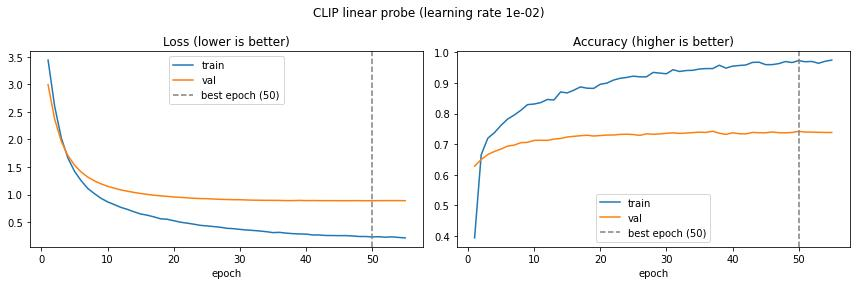

In [10]:
# Learning curves of the best run
h = pd.DataFrame({k: v for k, v in results_best.items() if k != "best_epoch"})
h.index = h.index + 1

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, metric in zip(axes, ["loss", "acc"]):
    ax.plot(h.index, h[f"train_{metric}"], label="train")
    ax.plot(h.index, h[f"val_{metric}"], label="val")
    ax.axvline(results_best["best_epoch"], color="gray", linestyle="--", label=f"best epoch ({results_best['best_epoch']})")
    ax.set_xlabel("epoch")
    ax.set_title({"loss": "Loss (lower is better)", "acc": "Accuracy (higher is better)"}[metric])
    ax.legend()
fig.suptitle(f"CLIP linear probe (learning rate {best['learning rate']:.0e})")
plt.tight_layout()
plt.show()

## 5. Comparison with our models

Our numbers come from `02_baseline`, `03_resnet` and `04_evaluate`.
Test scores exist only for the final ResNet18 (the test set was used once, for the model we chose).

In [11]:
same_scores = test_scores_of(head_same)
best_scores = test_scores_of(head_best)

comparison = pd.DataFrame({
    "model": ["SmallCNN (from scratch)",
              "ResNet18 phase 1",
              "ResNet18 phase 2 (fine-tuned)",
              "CLIP zero-shot",
              "CLIP probe (same settings)",
              f"CLIP probe (grid, lr {best['learning rate']:.0e})"],
    "trainable weights": ["428k", "24k", "11.2M", "0", "24k", "24k"],
    "val acc": [0.284, 0.562, 0.624, zs_val_acc, best_val_acc(results_same), best["val accuracy"]],
    "test acc": [None, None, 0.623, zs_test_acc, accuracy(same_scores, test_labels), accuracy(best_scores, test_labels)],
    "test top-3": [None, None, 0.826, zs_test_top3, top3_accuracy(same_scores, test_labels), top3_accuracy(best_scores, test_labels)],
})
comparison.style.format({"val acc": "{:.1%}", "test acc": "{:.1%}", "test top-3": "{:.1%}"}, na_rep="-")

,model,trainable weights,val acc,test acc,test top-3
0,SmallCNN (from scratch),428k,28.4%,-,-
1,ResNet18 phase 1,24k,56.2%,-,-
2,ResNet18 phase 2 (fine-tuned),11.2M,62.4%,62.3%,82.6%
3,CLIP zero-shot,0,43.9%,43.8%,64.4%
4,CLIP probe (same settings),24k,65.1%,63.9%,83.5%
5,"CLIP probe (grid, lr 1e-02)",24k,74.2%,74.1%,90.1%


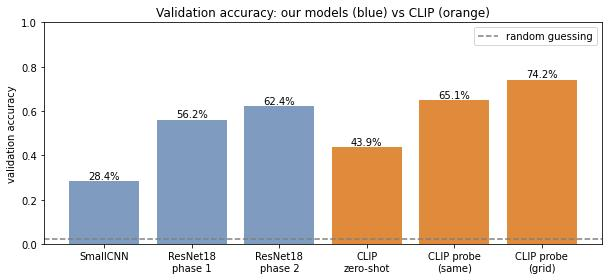

In [12]:
labels = ["SmallCNN", "ResNet18\nphase 1", "ResNet18\nphase 2", "CLIP\nzero-shot", "CLIP probe\n(same)", "CLIP probe\n(grid)"]
colors = ["#7f9cc0"] * 3 + ["#e08a3c"] * 3

plt.figure(figsize=(10, 4))
bars = plt.bar(labels, comparison["val acc"], color=colors)
plt.bar_label(bars, labels=[f"{v:.1%}" for v in comparison["val acc"]])
plt.axhline(1 / len(classes), color="gray", linestyle="--", label="random guessing")
plt.ylim(0, 1)
plt.ylabel("validation accuracy")
plt.title("Validation accuracy: our models (blue) vs CLIP (orange)")
plt.legend()
plt.show()

## 6. Speed and size

Single-image prediction on CPU (2 threads), the same way the web app works: preprocess + model + softmax.

In [13]:
def clip_predict(image):
    """Like infer.predict, but with CLIP + the probe. Returns (top-3 probabilities, seconds)."""
    start = time.perf_counter()
    x = clip_transform(image.convert("RGB")).unsqueeze(0)         # add a batch dimension
    with torch.inference_mode():
        image_features = make_unit_length(clip_model.encode_image(x))
        probs = torch.softmax(head_best(image_features), dim=1)[0]
    return probs.topk(3), time.perf_counter() - start


test_files = [Path(p) for p in datasets.DTD(DATA_DIR, split="test", partition=1)._image_files]
sample = np.random.default_rng(0).choice(len(test_files), size=30, replace=False)

resnet, _ = load_model(ROOT / "models" / "textag.pt")
predict(resnet, classes, Image.open(test_files[0]))     # warm-up
clip_predict(Image.open(test_files[0]))                  # warm-up

resnet_times = [predict(resnet, classes, Image.open(test_files[i]))[1] for i in sample]
clip_times = [clip_predict(Image.open(test_files[i]))[1] for i in sample]

resnet_weights = count_weights(resnet)
clip_weights = count_weights(clip_model.visual) + count_weights(head_best)
pd.DataFrame({
    "weights (millions)": [resnet_weights / 1e6, clip_weights / 1e6],
    "size (MB)": [resnet_weights * 4 / 1e6, clip_weights * 4 / 1e6],     # 4 bytes per weight
    "seconds per image (median)": [np.median(resnet_times), np.median(clip_times)],
}, index=["ResNet18 (fine-tuned)", "CLIP image encoder + probe"]).round(3)

,weights (millions),size (MB),seconds per image (median)
ResNet18 (fine-tuned),11.201,44.802,0.026
CLIP image encoder + probe,87.873,351.493,0.065


## 7. Text search demo

CLIP's real strength: search with **any words**, not just the 47 DTD classes.
Each query becomes 512 numbers and is compared with every test image; the top 5 are shown.
None of these queries are DTD classes.

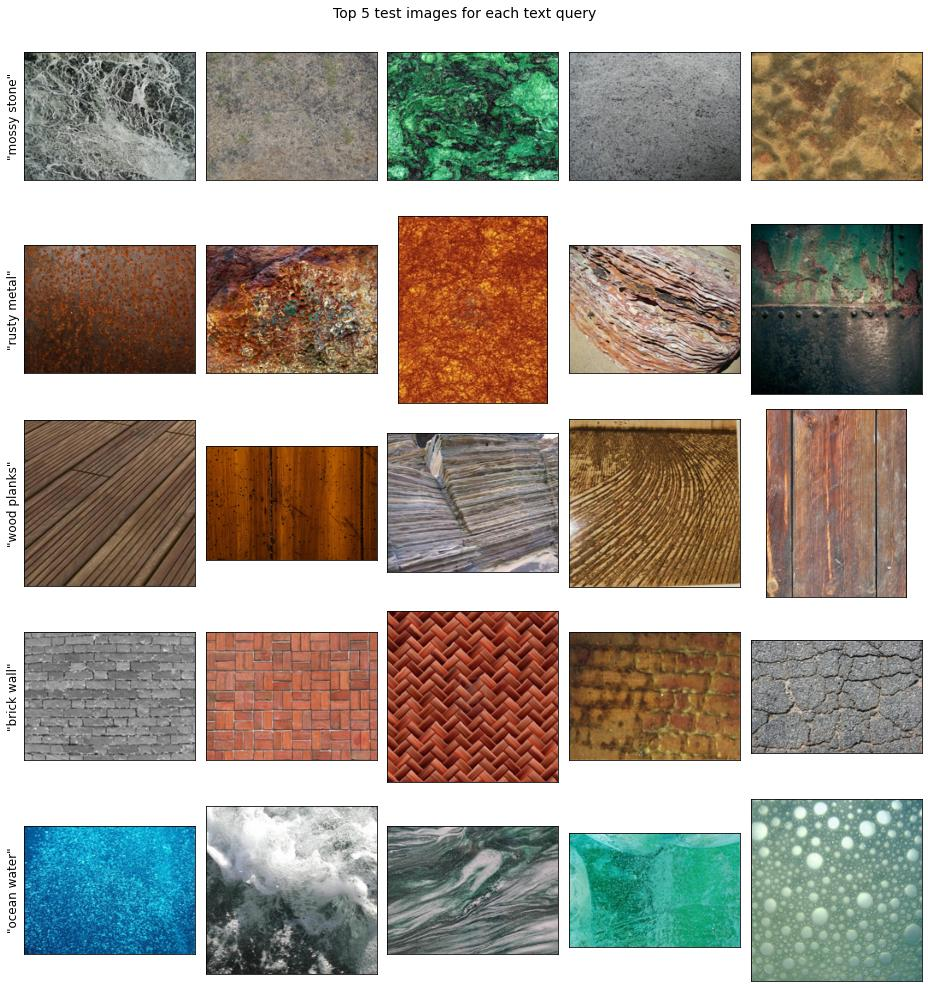

In [14]:
queries = ["mossy stone", "rusty metal", "wood planks", "brick wall", "ocean water"]

# 1. Queries -> 512 numbers each
with torch.inference_mode():
    query_features = clip_model.encode_text(tokenizer([f"a photo of {q}" for q in queries]))

# 2. Similarity of every query to every test image: (5 queries, 1880 images)
similarity = make_unit_length(query_features) @ make_unit_length(test_features).T

# 3. The 5 most similar images per query
top5 = similarity.topk(5, dim=1).indices

fig, axes = plt.subplots(len(queries), 5, figsize=(13, 2.8 * len(queries)))
for row, query in enumerate(queries):
    for col, i in enumerate(top5[row].tolist()):
        img = Image.open(test_files[i]).convert("RGB")
        img.thumbnail((200, 200))
        axes[row, col].imshow(img)
        axes[row, col].set_xticks([])
        axes[row, col].set_yticks([])
    axes[row, 0].set_ylabel(f'"{query}"', fontsize=12)
plt.suptitle("Top 5 test images for each text query", fontsize=14)
plt.tight_layout()
plt.show()

In [15]:
# Save the probe (small) in case the app switches to CLIP later
torch.save({"arch": "clip_vitb32_probe", "clip": ("ViT-B-32-quickgelu", "openai"),
            "state_dict": head_best.state_dict(), "classes": classes}, ROOT / "models" / "clip_probe.pt")
print("saved models/clip_probe.pt")

saved models/clip_probe.pt


## 8. Findings

- **The CLIP linear probe is the best model:** 74.1% test accuracy and 90.1% top-3, vs 62.3% / 82.6% for our fine-tuned ResNet18. Training just a 24k-weight last layer on frozen CLIP beat fine-tuning all 11.2M ResNet18 weights. What the backbone learned beforehand (400M image–caption pairs vs 1.2M labelled photos) mattered more than fine-tuning.
- **Like-for-like, CLIP features are better than ImageNet features:** with the exact ResNet phase-1 settings, the probe reaches 65.1% val vs 56.2% for ResNet18 phase 1 (same head, same training).
- **A grid search was cheap here:** with features computed once, each run takes seconds, so we tried 3 learning rates and picked 1e-2 on validation (test used once, at the end). For ResNet18, each run took minutes on a GPU.
- **Zero-shot, with no training at all, gets 43.8%** (about 21× random guessing). That's below every trained model on these 47 fixed classes, but it's the only one that works with any words. Wording matters: a sentence ("a cracked texture.", 43.9% val) beats the bare class name ("cracked", 41.3%).
- **Train/val gap, but no harmful overfitting:** train accuracy keeps rising (to ~97%) while val accuracy levels off around 73–74% after ~epoch 20. Val loss still inches down until epoch 50 and never rises, so early stopping kept epoch 50; stopping at ~20 would give nearly the same result (72.8% vs 74.2%).
- **Cost:** CLIP's image encoder is ~8× bigger (88M weights, ~350 MB vs 11M, ~45 MB) and ~3× slower per image on CPU (~0.06 s vs ~0.02 s in this run). Still fast enough for an app or for indexing a texture library.
- **Text search works with words outside DTD:** the top 5 for "rusty metal", "wood planks" and "brick wall" are clearly on target; "mossy stone" and "ocean water" are mixed. That's the search engine the game-engine plugin idea needs.

**Reference:** Radford et al. (2021), *Learning Transferable Visual Models From Natural Language Supervision* (CLIP).
[arXiv:2103.00020](https://arxiv.org/abs/2103.00020). Library: [OpenCLIP](https://github.com/mlfoundations/open_clip).